# Machine Learning Lab
## Experiment: 11 — Non-linear SVM with Polynomial and RBF Kernels

### Objective
Explore the kernel trick by training linear, degree-3 polynomial, and RBF SVM classifiers on a non-linearly separable synthetic dataset and comparing their decision boundaries.

### Learning outcomes
- Prepare data for a machine-learning workflow.
- Train and evaluate the required model(s).
- Interpret the results rather than relying only on accuracy.

### Environment
Recommended: Python 3.10+ with `numpy`, `pandas`, `matplotlib`, and `scikit-learn`.

## 1. Import libraries and generate data
`make_moons` produces two interleaving classes that are not well separated by a straight line.

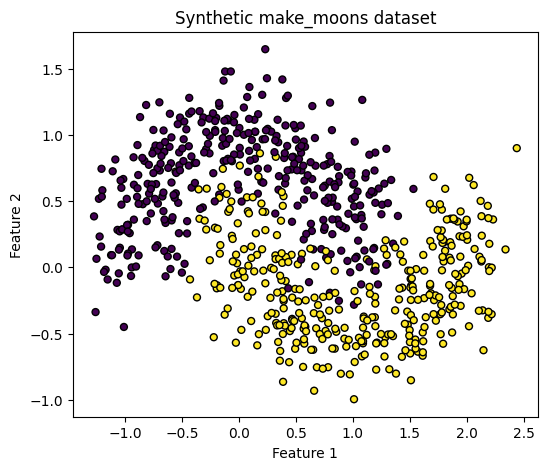

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

RANDOM_STATE = 42
X, y = make_moons(n_samples=700, noise=0.22, random_state=RANDOM_STATE)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis", edgecolor="k", s=25)
plt.title("Synthetic make_moons dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

## 2. Train three SVM models
- Linear kernel: creates a linear decision boundary in the original feature space.
- Polynomial kernel: degree 3 allows curved boundaries.
- RBF kernel: uses similarity based on distance and can model flexible non-linear boundaries.

In [2]:
models = {
    "Linear": make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0)),
    "Polynomial (degree 3)": make_pipeline(StandardScaler(), SVC(kernel="poly", degree=3, C=1.0, gamma="scale")),
    "RBF": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))
}

for model in models.values():
    model.fit(X_train, y_train)

## 3. Evaluate the models
Compare accuracy, precision, recall, and F1-score on the same held-out test set.

In [3]:
rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0)
    })
results = pd.DataFrame(rows).set_index("Model")
display(results)

,Accuracy,Precision,Recall,F1-score
Model,,,,
Linear,0.897143,0.887640,0.908046,0.897727
Polynomial (degree 3),0.885714,0.852632,0.931034,0.890110
RBF,0.937143,0.922222,0.954023,0.937853


## 4. Visualize decision boundaries
Each model is evaluated over the same mesh grid. The plot is a visualization of learned regions, not an additional test set.

C:\Users\ankit\AppData\Local\Temp\ipykernel_27872\3571909546.py:13: UserWarning: You passed a edgecolor/edgecolors ('white') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="viridis",
C:\Users\ankit\AppData\Local\Temp\ipykernel_27872\3571909546.py:13: UserWarning: You passed a edgecolor/edgecolors ('white') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="viridis",
C:\Users\ankit\AppData\Local\Temp\ipykernel_27872\3571909546.py:13: UserWarning: You passed a edgecolor/edgecolors ('white') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="viridis",


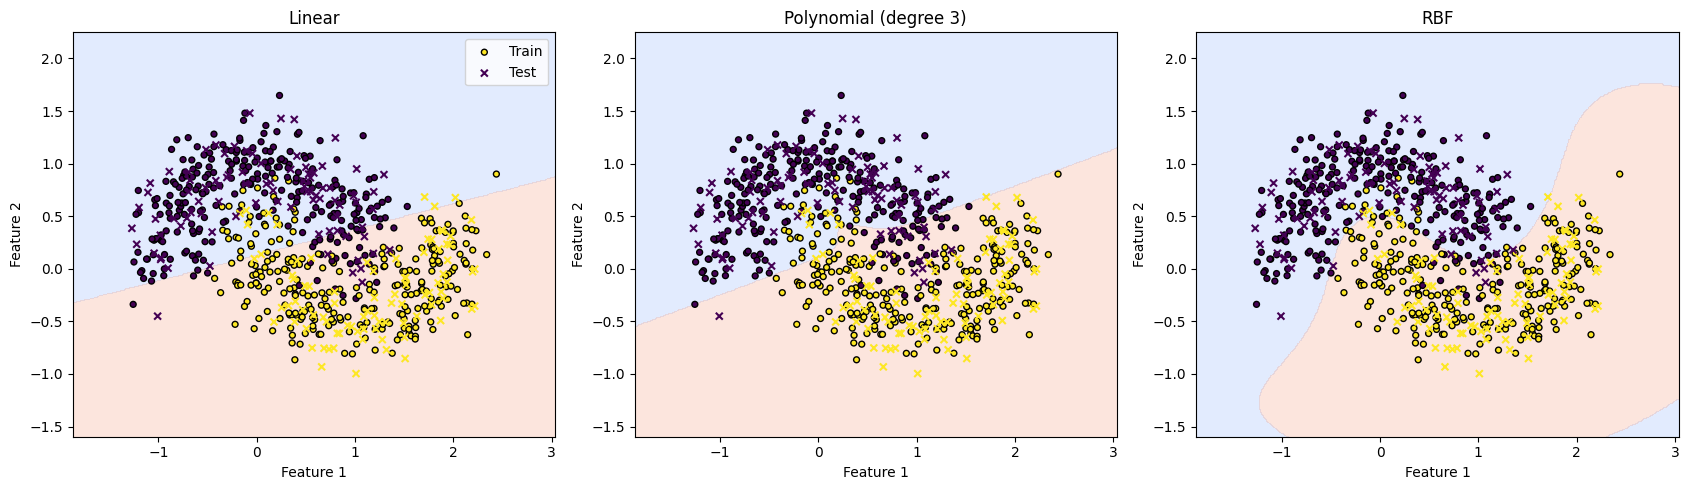

In [4]:
xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 0.6, X[:, 0].max() + 0.6, 350),
    np.linspace(X[:, 1].min() - 0.6, X[:, 1].max() + 0.6, 350)
)
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, model) in zip(axes, models.items()):
    zz = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, levels=[-0.5, 0.5, 1.5], cmap="coolwarm")
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="viridis",
               edgecolor="k", s=18, label="Train")
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="viridis",
               edgecolor="white", marker="x", s=25, label="Test")
    ax.set_title(name)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
axes[0].legend(loc="best")
plt.tight_layout()
plt.show()

## 5. Conclusion
Discuss which kernel performed best on this split, how the decision boundaries differ, and how `C` and `gamma` could cause underfitting or overfitting.